# Training the pix2pix de-anonymizer

One model is trained **per anonymization method**: a generator that undoes 8x8 pixelation has
learnt a different inverse than one that undoes a Gaussian blur, so `blackbar` and `pixelation`
get their own runs and their own checkpoints.

The pairs are made rather than collected. Every CelebA image is a target, and the input is that
same image with the pipeline's anonymizer applied to its detected facial area -- pixel-aligned by
construction, which is the supervision pix2pix's L1 term wants. The identities are deliberately
not the ones the experiment scores: an attacker may train on any face data, but training on
YouTube Faces would put the gallery into the generator's prior.

In [1]:
import pandas as pd
%load_ext autoreload
%autoreload 2

import logging

import torch
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader

from meles.frame_aggregation.pix2pix import LOAD_SIZE, load_generator, to_image
from meles.runtime.logs import ExtraFormatter
from meles.training import AnonymizedPairs, ImageArchive, Pix2PixTrainer, Slice, checkpoint_path, split

# Not logs.configure(): that dup2s stdout and stderr into a file, which is right for a Snakemake
# job and wrong for a notebook. The formatter is the part worth reusing -- it is what turns the
# extra={...} fields the library logs into readable key=value pairs.
handler = logging.StreamHandler()
handler.setFormatter(ExtraFormatter("%(asctime)s %(levelname)-7s %(name)s | %(message)s"))
logging.basicConfig(level=logging.INFO, handlers=[handler], force=True)

## The images

`torchvision.datasets.CelebA` is **not** used, and not because of a download failure. Its
integrity check demands five space-separated `.txt` annotation files matching exact MD5s of the
original Google Drive upload, and one of them (`identity_CelebA.txt`) is not in the Kaggle mirror
at all -- that mirror ships `.csv` instead. Any of them missing raises
`Dataset not found or corrupted`, which reads as a broken download but means "these are not the
bytes I expected". No file location fixes it.

None of that metadata is needed here: the pairs are made from the images alone. `ImageArchive`
reads them straight out of the zip, with no extraction and no assumption about how deeply a given
mirror nested them.

In [2]:
ANONYMIZER = "blackbar"                       # the method this run attacks; one checkpoint per method
ARCHIVE = "../../data/celeba/img_align_celeba.zip"    # or a directory: ImageDirectory("data/celeba/img_align_celeba")

# SEBA's regime. Its selector takes `ids: 20` and CelebA averages 19.9 images per identity, so its
# pix2pix trains on ~340 images; its sample config's `epochs: 100` splits into 50 + 50. That is
# ~40k steps, a few minutes. See Pix2PixTraining.md before changing any of this -- the numbers
# below only make sense together, and CORPUS is the one that decides what the run costs.
CORPUS = 400                                    # images before the train/val split; None for all
BATCH_SIZE = 1                                  # upstream's default, and load-bearing: see the doc
N_EPOCHS, N_EPOCHS_DECAY = 50, 50               # SEBA passes epochs//2 for both
TRAIN_RATE = 0.85                               # SEBA's split between train and val
WORKERS = 8

train_source, val_source = split(ImageArchive(ARCHIVE), validation=1 - TRAIN_RATE)
if CORPUS is not None:
    # 'split' permutes with a fixed seed, so taking a prefix of each half is a reproducible random
    # subsample rather than whatever happened to sort first in the archive.
    train_source = Slice(train_source, range(round(CORPUS * TRAIN_RATE)))
    val_source = Slice(val_source, range(round(CORPUS * (1 - TRAIN_RATE))))

# 'load_size' turns on upstream's resize_and_crop: scale to 286, take a random 256 crop, mirror at
# random -- pix2pix's entire augmentation, drawn once per pair and applied to both ends. Off for
# validation, so that its loss is comparable between epochs rather than measured on a fresh crop.
train_pairs = AnonymizedPairs(train_source, ANONYMIZER, load_size=LOAD_SIZE, flip=True)
val_pairs = AnonymizedPairs(val_source, ANONYMIZER, load_size=None)

steps = len(train_pairs) * (N_EPOCHS + N_EPOCHS_DECAY)
print(f"{len(train_pairs)} training and {len(val_pairs)} validation images")
print(f"{steps:,} optimiser steps over {N_EPOCHS + N_EPOCHS_DECAY} epochs at batch size {BATCH_SIZE}")

2026-09-16 12:54:36,088 INFO    meles.training.sources | Read image archive path='../../data/celeba/img_align_celeba.zip' len=202599


340 training and 60 validation images
34,000 optimiser steps over 100 epochs at batch size 1


In [3]:
# Detect once, here in the parent process, rather than once per image per epoch in the workers.
# Roughly two minutes over CelebA on eight threads. It also gives an honest miss count -- a high
# one means the pairs are mostly whole-image anonymizations rather than face anonymizations, which
# is not the attack being modelled.
train_pairs.detect()
val_pairs.detect()

print(f"train {len(train_pairs)} pairs, {train_pairs.missing} without a detected face")
print(f"val   {len(val_pairs)} pairs, {val_pairs.missing} without a detected face")

Detecting (blackbar): 100%|██████████| 340/340 [00:09<00:00, 34.16it/s]
2026-09-16 12:54:48,178 INFO    meles.training.pairs | Detected faces for the training pairs anonymizer='blackbar' len=340 no_face=0
Detecting (blackbar): 100%|██████████| 60/60 [00:00<00:00, 556.64it/s]
2026-09-16 12:54:48,326 INFO    meles.training.pairs | Detected faces for the training pairs anonymizer='blackbar' len=60 no_face=0


train 340 pairs, 0 without a detected face
val   60 pairs, 0 without a detected face


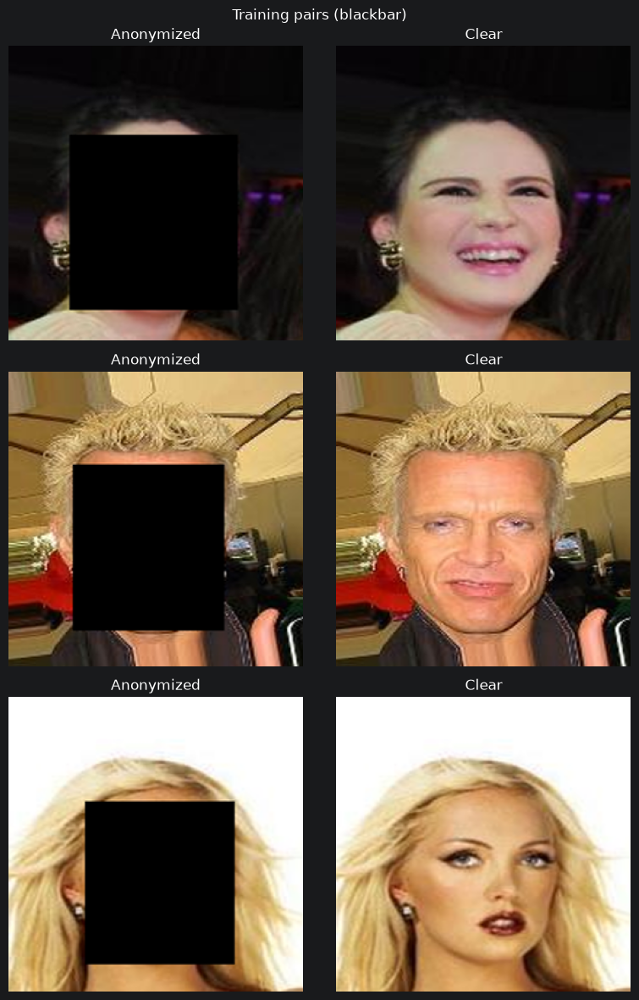

In [4]:
def show(pairs, model=None, count=3, title="Pairs"):
    """Input / target / (optionally) generated, as images rather than tensors."""
    columns = 3 if model is not None else 2
    figure, axes = plt.subplots(count, columns, figsize=(4 * columns, 4 * count), squeeze=False)
    figure.suptitle(title)

    # Rendered in eval mode, and restored afterwards. pix2pix keeps dropout on at test time and
    # 'deanonymize' follows it -- but that makes every render a fresh sample: two renders of the
    # *same* model and image differ by ~0.008 mean absolute, against 0.014 for the entire
    # epoch-20-to-100 improvement. Comparing epochs by eye is hopeless unless this is deterministic.
    was_training = model.training if model is not None else False
    if model is not None:
        model.eval()

    try:
        for row in range(count):
            anonymized, clear = pairs[row]
            panels = [(anonymized, "Anonymized"), (clear, "Clear")]
            if model is not None:
                with torch.no_grad():
                    device = next(model.parameters()).device
                    panels.append((model(anonymized[None].to(device))[0], "Generated"))
            for column, (tensor, name) in enumerate(panels):
                # to_image returns BGR, which is what the whole pipeline speaks; matplotlib wants RGB.
                axes[row][column].imshow(to_image(tensor)[:, :, ::-1])
                axes[row][column].set_title(name)
                axes[row][column].axis("off")
    finally:
        if model is not None:
            model.train(was_training)

    plt.tight_layout()
    plt.show()


show(train_pairs, title=f"Training pairs ({ANONYMIZER})")

## The run

`Pix2PixTrainer.resume` picks a checkpoint back up if one is there, so re-running this cell after
an interruption continues the run instead of silently restarting at epoch 0. `fit` writes the
checkpoint after every epoch.

In [5]:
# No 'drop_last': upstream's batch_size is 1, and the U-Net tolerates it because the innermost
# encoder block -- the one running at 1x1, where a BatchNorm would raise on a single sample -- is
# the one block pix2pix leaves unnormalised.
train_loader = DataLoader(
    train_pairs,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=WORKERS,
    persistent_workers=WORKERS > 0,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_pairs,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=WORKERS,
    persistent_workers=WORKERS > 0,
    pin_memory=torch.cuda.is_available(),
)

trainer = Pix2PixTrainer.resume(ANONYMIZER, n_epochs=N_EPOCHS, n_epochs_decay=N_EPOCHS_DECAY)
print(f"{trainer.anonymizer} on {trainer.device}, epoch {trainer.epoch}/{trainer.epochs}")

blackbar on cuda, epoch 0/100


Training blackbar 1/100: 100%|██████████| 340/340 [00:08<00:00, 39.05it/s]
2026-09-16 12:55:03,692 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=1 lr=0.0002 train_l1=0.23839 val_l1=0.22623 train_adv=0.9927 train_d=0.6596
2026-09-16 12:55:05,000 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=1
Training blackbar 2/100: 100%|██████████| 340/340 [00:06<00:00, 48.83it/s]
2026-09-16 12:55:12,298 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=2 lr=0.0002 train_l1=0.17126 val_l1=0.16747 train_adv=1.3623 train_d=0.5493
2026-09-16 12:55:14,807 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=2
Training blackbar 3/100: 100%|██████████| 340/340 [00:06<00:00, 51.67it/s]
2026-09-16 12:55:21,754 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=3 lr=0.0002 trai

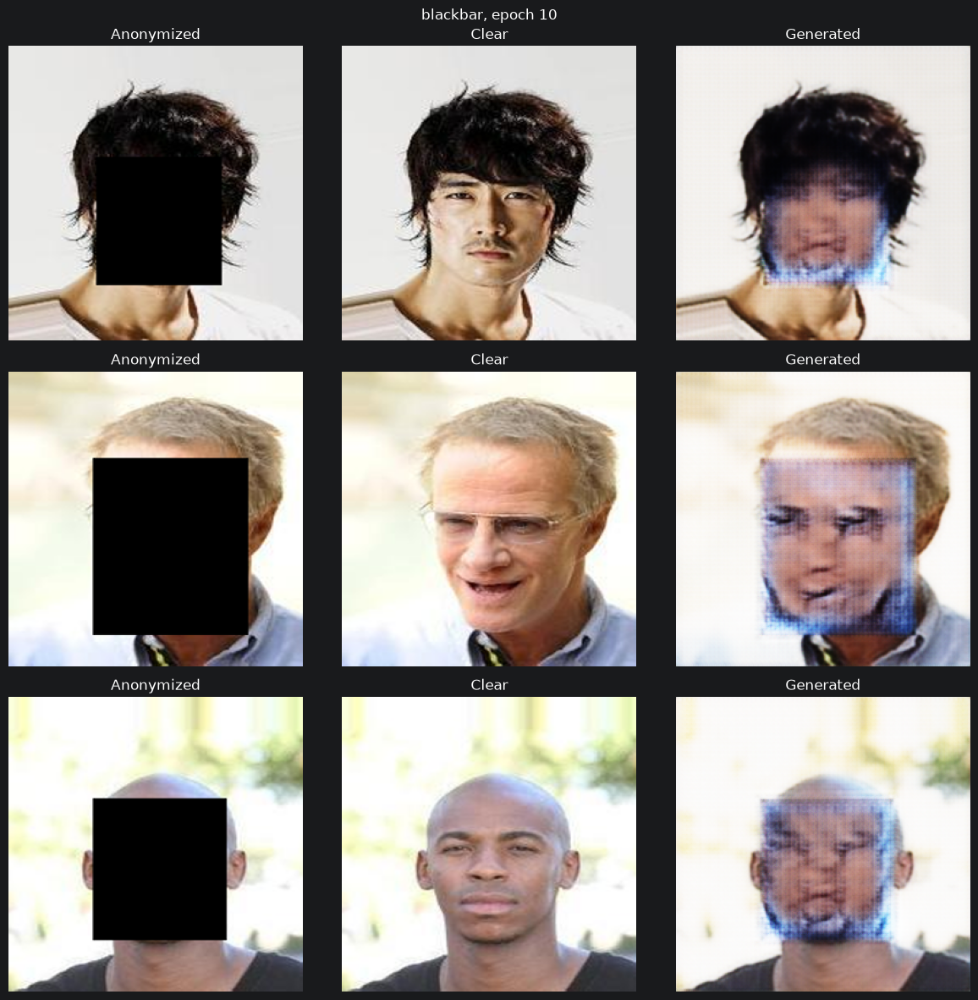

Training blackbar 11/100: 100%|██████████| 340/340 [00:07<00:00, 47.97it/s]
2026-09-16 12:56:32,750 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=11 lr=0.0002 train_l1=0.13061 val_l1=0.1562 train_adv=1.2982 train_d=0.5465
2026-09-16 12:56:34,668 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=11
Training blackbar 12/100: 100%|██████████| 340/340 [00:06<00:00, 50.36it/s]
2026-09-16 12:56:41,752 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=12 lr=0.0002 train_l1=0.12952 val_l1=0.23489 train_adv=1.3188 train_d=0.5515
2026-09-16 12:56:43,670 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=12
Training blackbar 13/100: 100%|██████████| 340/340 [00:06<00:00, 48.81it/s]
2026-09-16 12:56:50,960 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=13 lr=0.00

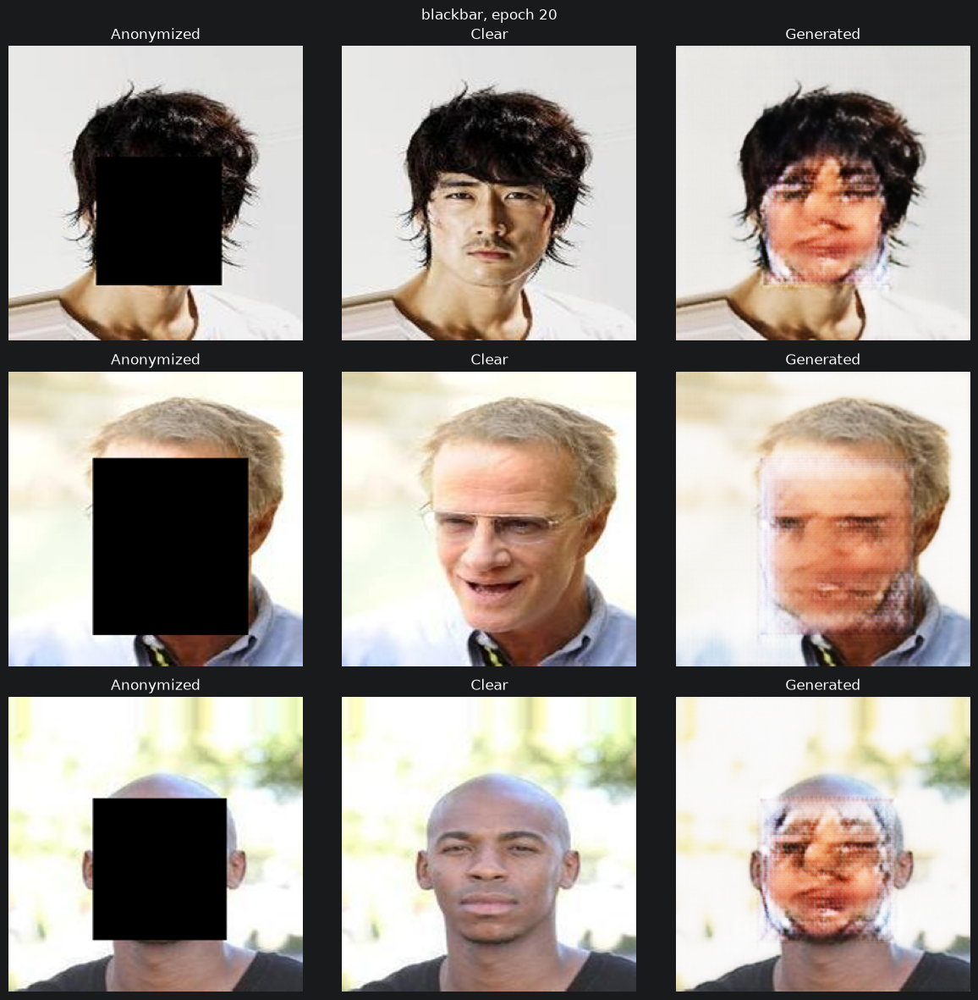

Training blackbar 21/100: 100%|██████████| 340/340 [00:06<00:00, 52.93it/s]
2026-09-16 12:58:01,211 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=21 lr=0.0002 train_l1=0.11828 val_l1=0.09859 train_adv=1.7878 train_d=0.473
2026-09-16 12:58:03,112 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=21
Training blackbar 22/100: 100%|██████████| 340/340 [00:06<00:00, 53.50it/s]
2026-09-16 12:58:09,765 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=22 lr=0.0002 train_l1=0.11612 val_l1=0.22578 train_adv=1.7245 train_d=0.4861
2026-09-16 12:58:11,714 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=22
Training blackbar 23/100: 100%|██████████| 340/340 [00:06<00:00, 48.70it/s]
2026-09-16 12:58:19,029 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=23 lr=0.00

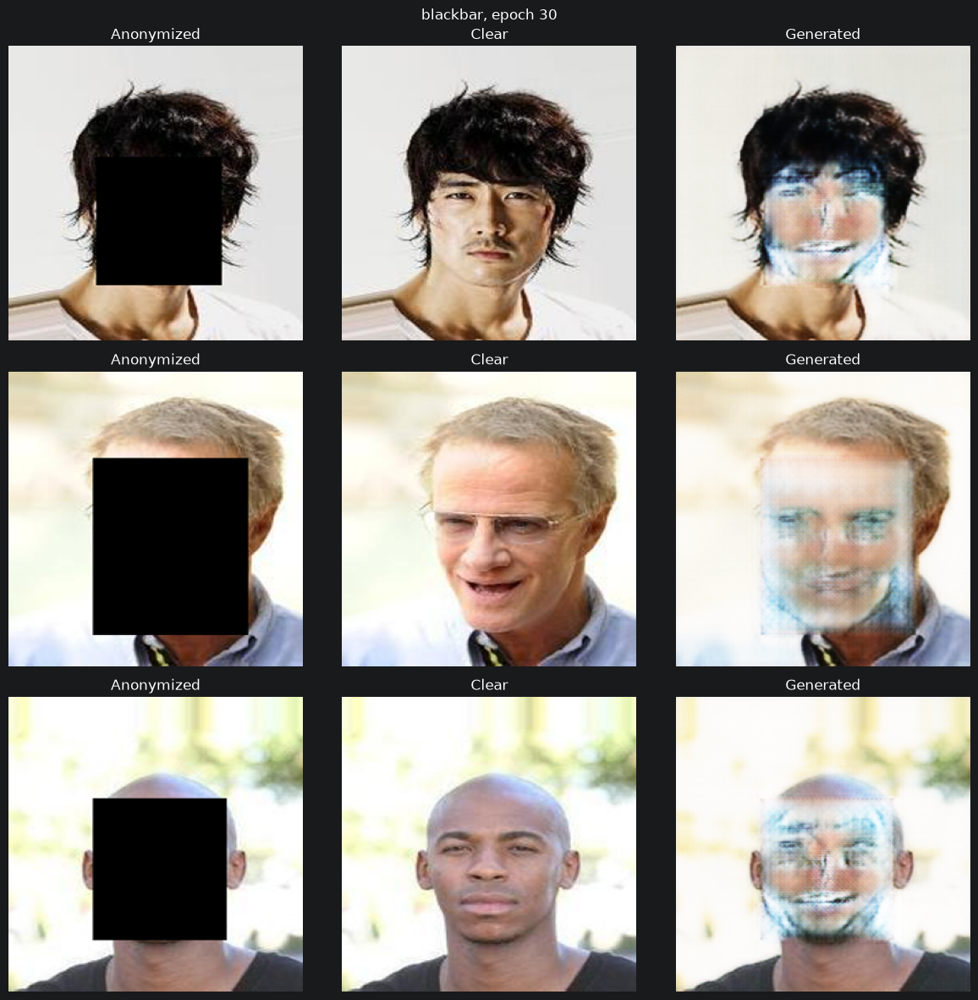

Training blackbar 31/100: 100%|██████████| 340/340 [00:06<00:00, 53.94it/s]
2026-09-16 12:59:27,946 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=31 lr=0.0002 train_l1=0.10921 val_l1=0.19691 train_adv=1.9994 train_d=0.4465
2026-09-16 12:59:29,820 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=31
Training blackbar 32/100: 100%|██████████| 340/340 [00:06<00:00, 52.08it/s]
2026-09-16 12:59:36,667 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=32 lr=0.0002 train_l1=0.10684 val_l1=0.09089 train_adv=2.1122 train_d=0.4204
2026-09-16 12:59:38,585 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=32
Training blackbar 33/100: 100%|██████████| 340/340 [00:06<00:00, 51.91it/s]
2026-09-16 12:59:45,503 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=33 lr=0.0

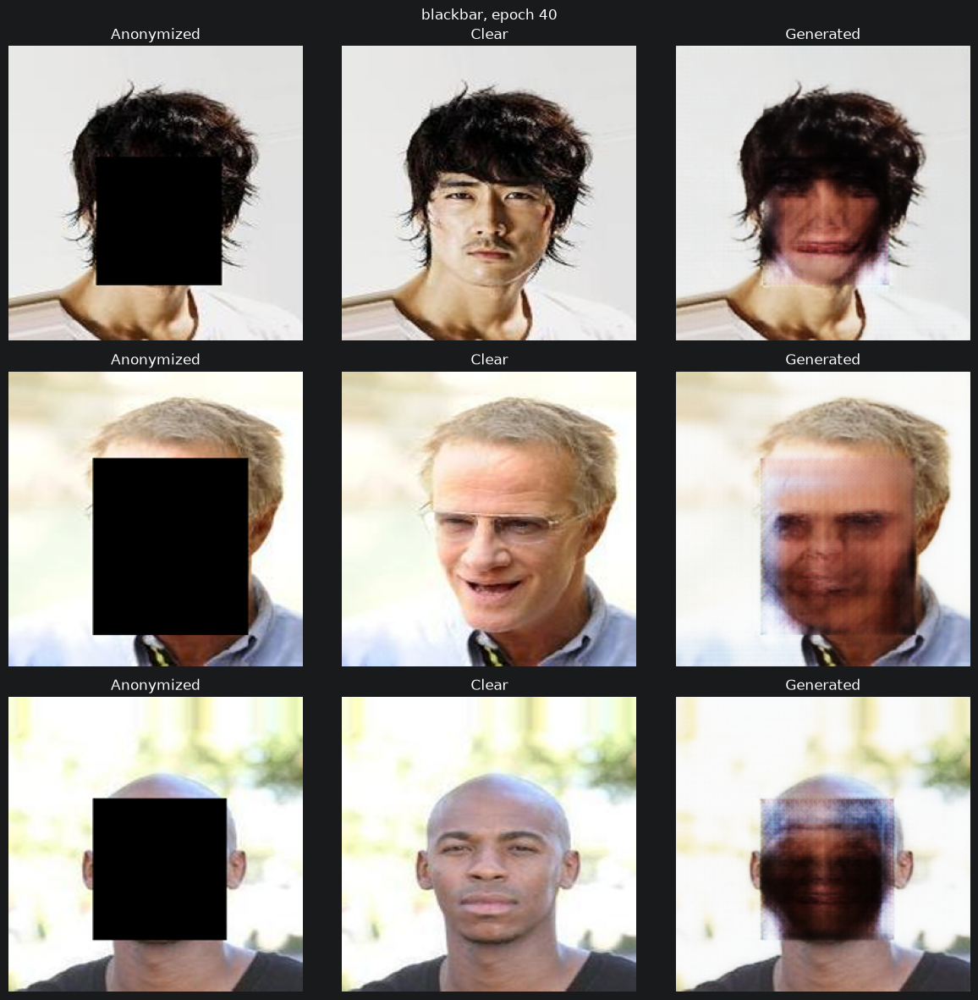

Training blackbar 41/100: 100%|██████████| 340/340 [00:06<00:00, 50.09it/s]
2026-09-16 13:00:57,755 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=41 lr=0.0002 train_l1=0.10286 val_l1=0.09534 train_adv=2.5796 train_d=0.3822
2026-09-16 13:00:59,643 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=41
Training blackbar 42/100: 100%|██████████| 340/340 [00:06<00:00, 49.53it/s]
2026-09-16 13:01:06,844 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=42 lr=0.0002 train_l1=0.10165 val_l1=0.10097 train_adv=2.306 train_d=0.4159
2026-09-16 13:01:08,763 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=42
Training blackbar 43/100: 100%|██████████| 340/340 [00:06<00:00, 49.64it/s]
2026-09-16 13:01:16,022 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=43 lr=0.00

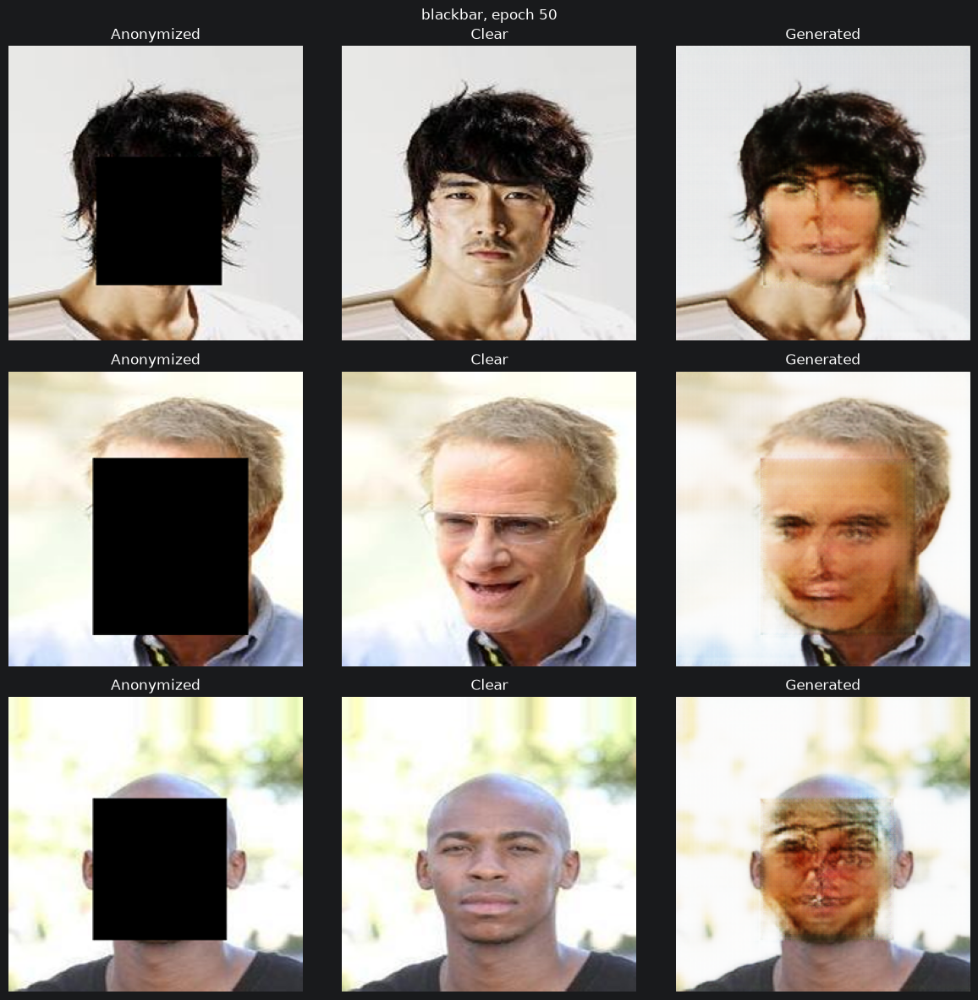

Training blackbar 51/100: 100%|██████████| 340/340 [00:06<00:00, 56.31it/s]
2026-09-16 13:02:32,032 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=51 lr=0.00019608 train_l1=0.09939 val_l1=0.0879 train_adv=3.0681 train_d=0.2909
2026-09-16 13:02:33,874 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=51
Training blackbar 52/100: 100%|██████████| 340/340 [00:05<00:00, 60.37it/s]
2026-09-16 13:02:39,817 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=52 lr=0.00019216 train_l1=0.09779 val_l1=0.08647 train_adv=3.0319 train_d=0.3433
2026-09-16 13:02:41,702 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=52
Training blackbar 53/100: 100%|██████████| 340/340 [00:06<00:00, 55.99it/s]
2026-09-16 13:02:48,068 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=53

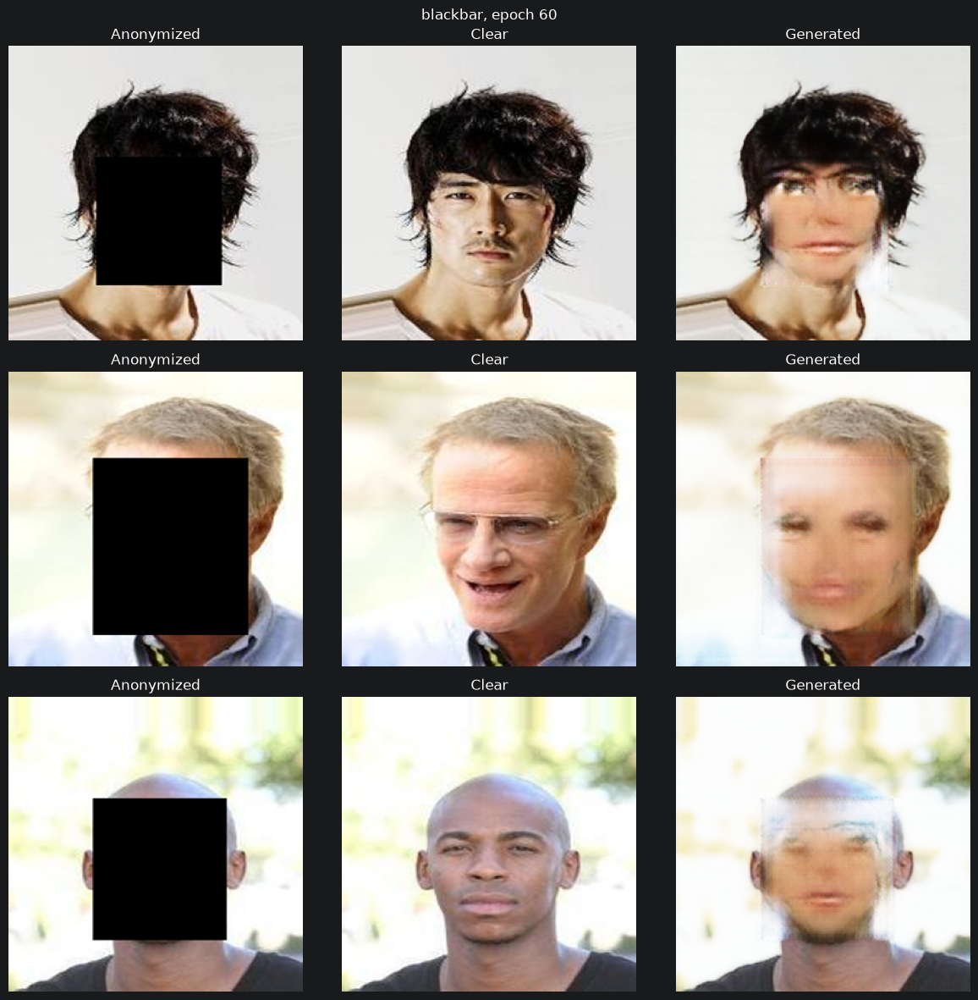

Training blackbar 61/100: 100%|██████████| 340/340 [00:06<00:00, 56.46it/s]
2026-09-16 13:04:03,573 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=61 lr=0.00015686 train_l1=0.09295 val_l1=0.09551 train_adv=3.4481 train_d=0.291
2026-09-16 13:04:05,447 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=61
Training blackbar 62/100: 100%|██████████| 340/340 [00:05<00:00, 60.65it/s]
2026-09-16 13:04:11,322 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=62 lr=0.00015294 train_l1=0.09209 val_l1=0.08662 train_adv=3.4757 train_d=0.2346
2026-09-16 13:04:13,216 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=62
Training blackbar 63/100: 100%|██████████| 340/340 [00:05<00:00, 58.05it/s]
2026-09-16 13:04:19,354 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=63

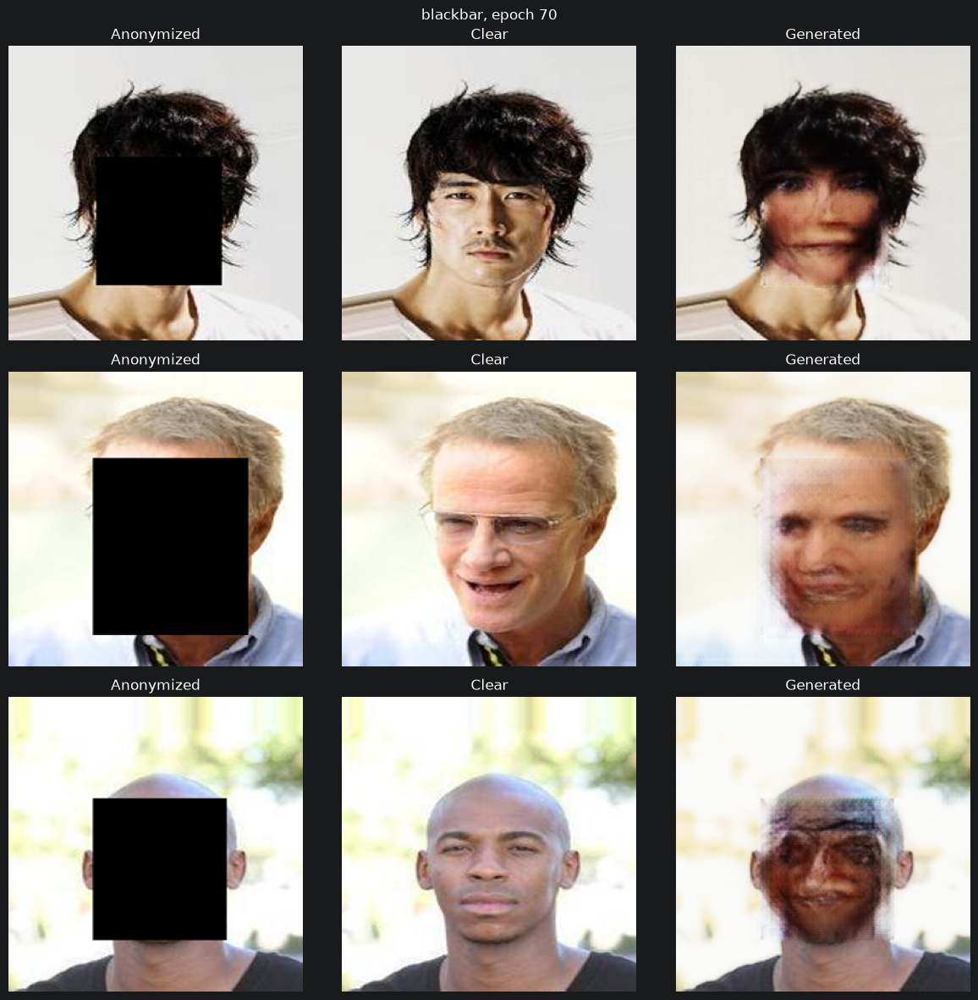

Training blackbar 71/100: 100%|██████████| 340/340 [00:05<00:00, 57.61it/s]
2026-09-16 13:05:24,566 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=71 lr=0.00011765 train_l1=0.08889 val_l1=0.17008 train_adv=4.0848 train_d=0.1467
2026-09-16 13:05:26,466 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=71
Training blackbar 72/100: 100%|██████████| 340/340 [00:05<00:00, 60.51it/s]
2026-09-16 13:05:32,373 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=72 lr=0.00011373 train_l1=0.0892 val_l1=0.14768 train_adv=4.1354 train_d=0.1581
2026-09-16 13:05:34,390 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=72
Training blackbar 73/100: 100%|██████████| 340/340 [00:05<00:00, 57.95it/s]
2026-09-16 13:05:40,549 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=73

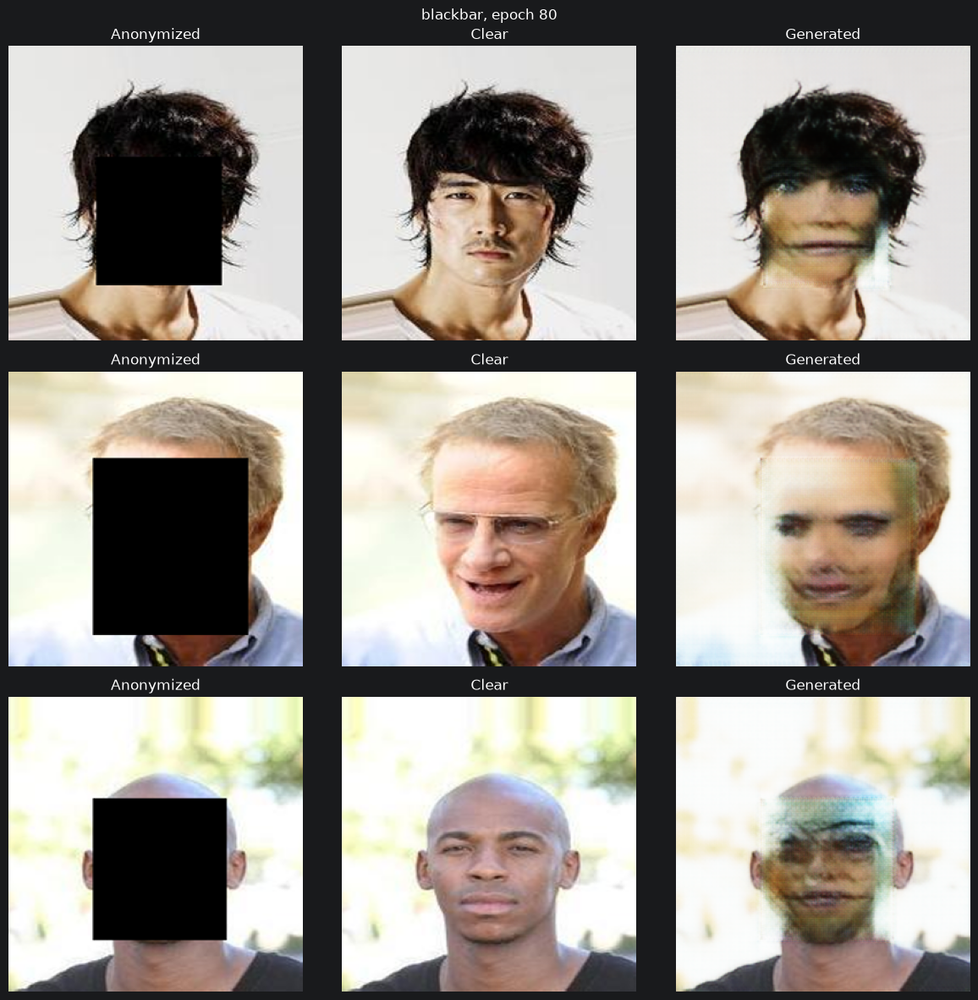

Training blackbar 81/100: 100%|██████████| 340/340 [00:06<00:00, 55.84it/s]
2026-09-16 13:06:56,361 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=81 lr=7.843e-05 train_l1=0.0856 val_l1=0.09353 train_adv=4.8591 train_d=0.0811
2026-09-16 13:06:58,253 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=81
Training blackbar 82/100: 100%|██████████| 340/340 [00:05<00:00, 58.09it/s]
2026-09-16 13:07:04,386 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=82 lr=7.451e-05 train_l1=0.08513 val_l1=0.08509 train_adv=5.1897 train_d=0.0978
2026-09-16 13:07:06,321 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=82
Training blackbar 83/100: 100%|██████████| 340/340 [00:05<00:00, 56.99it/s]
2026-09-16 13:07:12,576 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=83 l

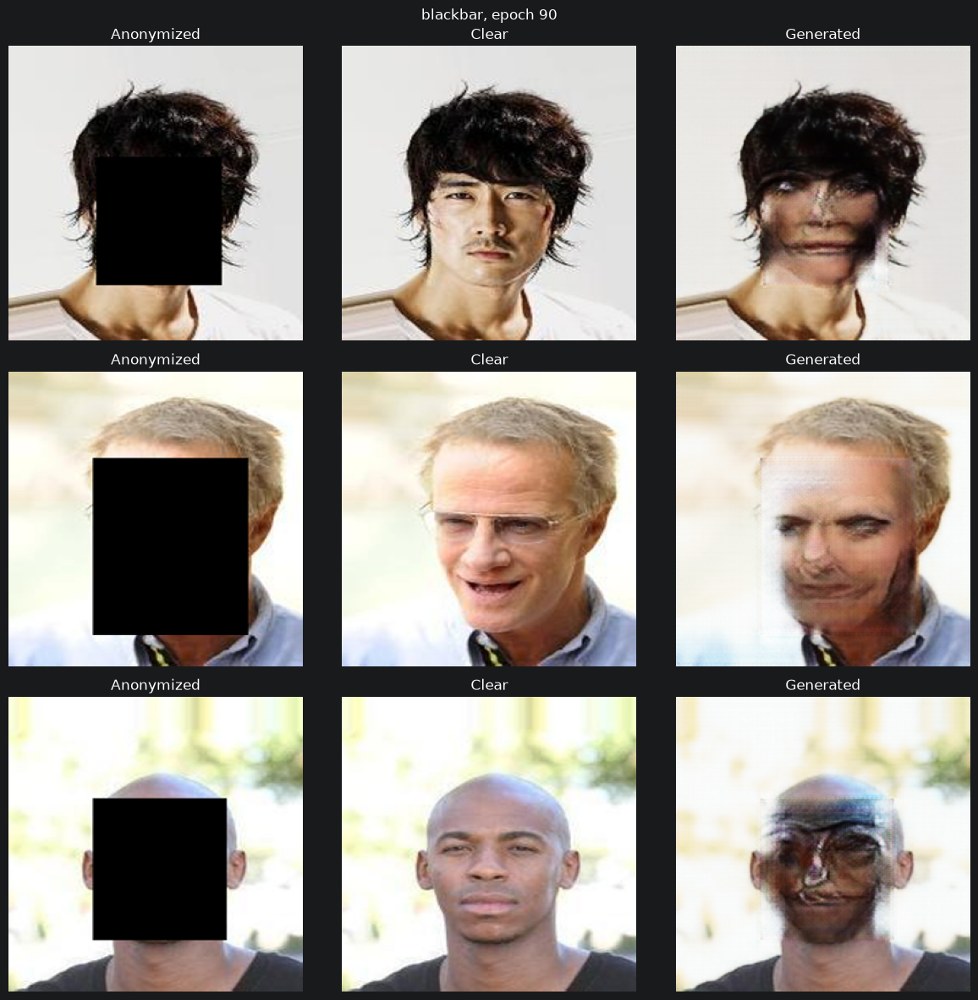

Training blackbar 91/100: 100%|██████████| 340/340 [00:06<00:00, 54.78it/s]
2026-09-16 13:08:18,862 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=91 lr=3.922e-05 train_l1=0.08336 val_l1=0.09949 train_adv=5.3911 train_d=0.0453
2026-09-16 13:08:20,730 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=91
Training blackbar 92/100: 100%|██████████| 340/340 [00:06<00:00, 56.54it/s]
2026-09-16 13:08:27,077 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=92 lr=3.529e-05 train_l1=0.08599 val_l1=0.092 train_adv=5.8724 train_d=0.0262
2026-09-16 13:08:28,944 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.pt' anonymizer='blackbar' epoch=92
Training blackbar 93/100: 100%|██████████| 340/340 [00:05<00:00, 58.64it/s]
2026-09-16 13:08:35,013 INFO    meles.training.pix2pix | Trained epoch anonymizer='blackbar' epoch=93 lr

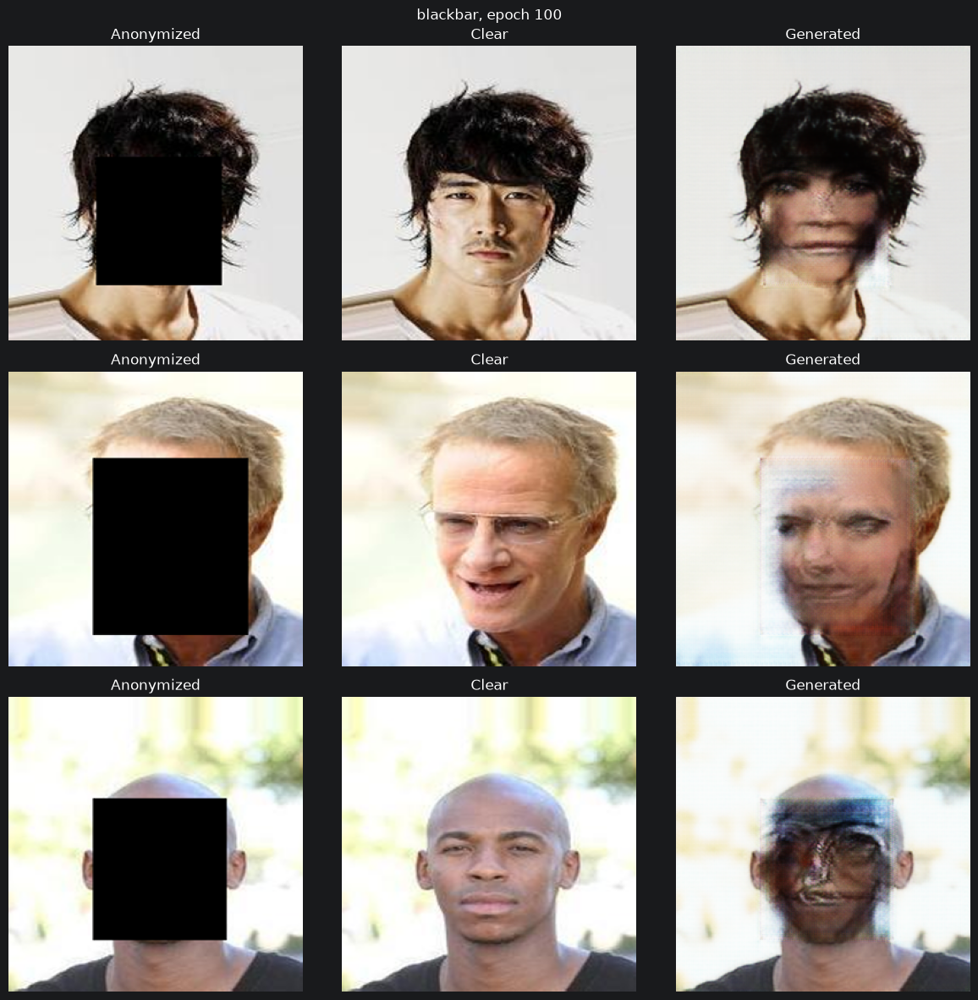

2026-09-16 13:09:34,194 INFO    meles.training.pix2pix | Training completed anonymizer='blackbar' epochs=None seconds=882.2


In [6]:
def preview(trainer, epoch, every=10):
    if epoch % every == 0:
        show(val_pairs, trainer.generator, title=f"{trainer.anonymizer}, epoch {epoch}")


# No 'epochs': runs out the n_epochs + n_epochs_decay schedule. Stopping short would leave the
# learning rate part-way down its ramp, which is a different model than the schedule describes.
history = trainer.fit(
    train_loader,
    val_loader,
    on_epoch=preview,
    checkpoint=checkpoint_path(ANONYMIZER),
)

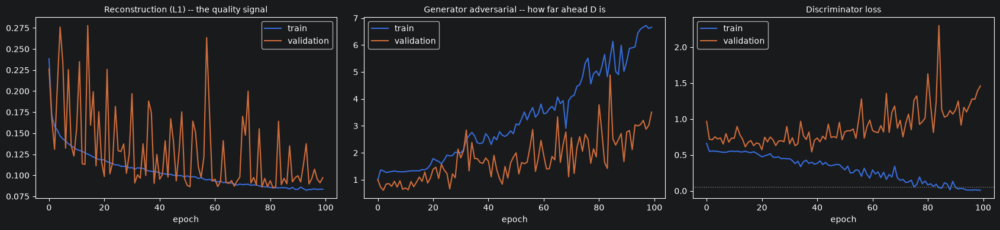

In [7]:
# Read 'l1' first and the other two as diagnostics. The generator total (adversarial + 100*l1) is
# the thing being optimised but says nothing on its own: it rises whenever the discriminator pulls
# ahead, so a run whose reconstruction is steadily improving still plots as a rising curve.
panels = [
    ("l1", "Reconstruction (L1) -- the quality signal"),
    ("adv", "Generator adversarial -- how far ahead D is"),
    ("d", "Discriminator loss"),
]
figure, axes = plt.subplots(1, 3, figsize=(17, 4))
for axis, (series, title) in zip(axes, panels):
    axis.plot(history[f"train_{series}"], label="train")
    axis.plot(history[f"val_{series}"], label="validation")
    axis.set_title(title, fontsize=10)
    axis.set_xlabel("epoch")
    axis.legend()

# A discriminator that has won sits near zero while the generator's adversarial term climbs. The
# run does not fail -- L1 keeps it producing faces -- but the adversarial half has stopped
# contributing. pix2pix offers no brake for that, and SEBA runs it at its defaults.
axes[2].axhline(0.05, color="grey", linestyle=":", linewidth=1)
plt.tight_layout()
plt.show()

## Export and import

`trainer.save()` writes generator, discriminator, both optimisers and the loss history, which is
what makes a run resumable. `inference_only=True` drops everything but the generator (207 MiB
instead of 654). Either file records which anonymization it was trained against, and
`load_generator` refuses to hand back a model for a method it was not trained on -- pointing a
pixelation model at blurred frames produces plausible output and a meaningless score.

2026-09-16 13:09:35,186 INFO    meles.frame_aggregation.pix2pix | Saved pix2pix checkpoint path='models/pix2pix/blackbar.generator.pt' anonymizer='blackbar' epoch=100


models/pix2pix/blackbar.generator.pt 208 MiB


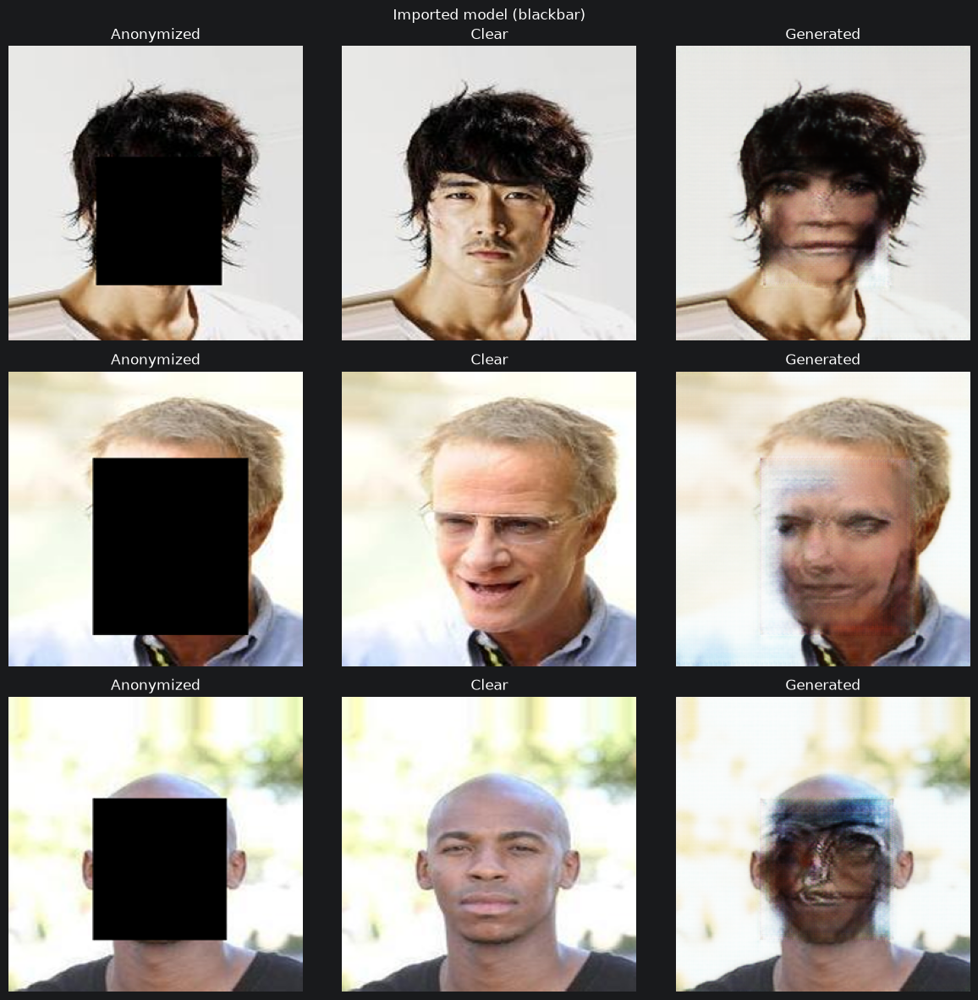

In [8]:
path = trainer.save(checkpoint_path(ANONYMIZER).with_suffix(".generator.pt"), inference_only=True)
print(path, f"{path.stat().st_size / 1024 ** 2:.0f} MiB")

generator = load_generator(path, device=trainer.device, anonymizer=ANONYMIZER)
show(val_pairs, generator, title=f"Imported model ({ANONYMIZER})")

In [9]:
# 'deanonymize' is the inference entry point the frame aggregator will call: frames in, frames
# out, BGR uint8, each resized back to the size it arrived at.
anonymized = [to_image(val_pairs[index][0]) for index in range(4)]
restored = generator.deanonymize(anonymized)
print([frame.shape for frame in restored])

[(256, 256, 3), (256, 256, 3), (256, 256, 3), (256, 256, 3)]


In [10]:
import pandas as pd

history_df = pd.DataFrame(history)
history_df.to_csv("history.csv", index=True)
history_df

,train_g,train_d,train_adv,train_l1,val_g,val_d,val_adv,val_l1
0,24.831821,0.659575,0.992722,0.238391,23.628840,0.967107,1.005782,0.226231
1,18.488243,0.549310,1.362289,0.171260,17.476158,0.717475,0.729297,0.167469
2,17.141251,0.552642,1.329864,0.158114,13.688914,0.709540,0.610801,0.130781
3,16.624766,0.550838,1.267654,0.153571,21.356174,0.750985,0.837171,0.205190
4,15.953454,0.548026,1.289954,0.146635,28.457656,0.721230,0.856344,0.276013
...,...,...,...,...,...,...,...,...
95,14.926875,0.010986,6.592838,0.083340,12.643925,1.185160,3.046796,0.095971
96,15.047086,0.008220,6.659190,0.083879,13.931163,1.277498,3.204244,0.107269
97,15.038910,0.013880,6.721409,0.083175,12.407513,1.274264,2.874941,0.095326
98,14.965833,0.009849,6.612487,0.083533,12.134755,1.393763,3.023747,0.091110
